# CryptoRisk Lab: Bitcoin Downside Risk Simulation

**Research question:** To what extent does a two-state Markov regime-switching model improve 30-day Bitcoin downside-risk estimation compared with a constant-volatility geometric Brownian motion (GBM) baseline?

**Project overview.** CryptoRisk Lab will analyse historical BTC/USDT returns, estimate the probabilities of switching between calmer and more volatile market conditions, simulate alternative 30-day investment outcomes, and compare downside-risk estimates from two models. The intended measures are the probability of exceeding a loss threshold, 95% Value at Risk (VaR), and 95% Expected Shortfall (ES). A later evaluation will compare model outputs with historical observations excluded from calibration.

> **Development status: Day 2 — historical data analysis completed.** Daily BTC/USDT prices for 2022–2025 have been downloaded and validated. Daily returns, rolling volatility, descriptive visualisations, and the calibration/evaluation split are implemented. The GBM and two-state Markov simulators, risk metrics, and final model comparison are not yet implemented. Earlier fictional examples are retained as introductory exercises.
  

### Setup and reproducibility

Use Python and common scientific libraries available in free Google Colab. `SEED` is fixed for reproducibility. When external packages are needed later, install them in the first code cell.

In [11]:
# Day 1 setup: no extra package installation required in Google Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

print(f"NumPy {np.__version__}; Pandas {pd.__version__}")
print(f"Random seed: {SEED}")

NumPy 2.4.6; Pandas 2.2.3
Random seed: 42


## 1. Problem and question

Bitcoin returns sometimes exhibit relatively calm periods and sometimes much larger fluctuations. A constant-volatility GBM model treats daily log returns as draws from **one** fixed distribution; a two-state Markov model instead allows the distribution to depend on whether the market is currently in a low- or high-volatility state.

The goal is **not** to forecast a single future Bitcoin price or recommend trades. We will ask whether explicitly modelling changing market conditions materially changes, and potentially improves, estimates of **30-day downside risk**.

**Planned fair comparison**

| Design choice | Decision |
|---|---|
| Asset | Spot BTC/USDT, USDT-denominated (not automatically interchangeable with USD) |
| Calibration data | Daily prices from 2022–2024 |
| Held-out evaluation | Daily prices from 2025, not used for fitting |
| Investment example | 1,000 USDT; adjustable in the final demo |
| Main horizon | 30 days |
| Model A | Constant-volatility GBM |
| Model B | Two-state Markov regime switching |
| Main measures | Loss-threshold exceedance, 95% VaR, 95% ES |
| Numerical experiment | Monte Carlo with recorded seeds, replications and uncertainty intervals |

**Important scientific distinction:** Finding a different estimate is not proof that one model is more accurate. We need verification of our implementation and a clearly limited, separate evaluation against held-out observations.

### Day 1 exercise: simple returns and log returns

For strictly positive daily prices $P_t$ (USDT per BTC), a **simple return** is

$$R_t=\frac{P_t-P_{t-1}}{P_{t-1}},$$

and a **log return** is

$$r_t=\ln\!\left(\frac{P_t}{P_{t-1}}\right)=\ln(1+R_t).$$

Log returns are dimensionless and add over consecutive periods. The next cell uses small **fictional prices for learning only**, not market data.

In [12]:
def simple_returns(prices):
    """Calculate simple returns from a 1D series of positive daily prices."""
    prices = np.asarray(prices, dtype=float)
    if prices.ndim != 1 or prices.size < 2 or not np.all(np.isfinite(prices)) or np.any(prices <= 0):
        raise ValueError("Expected at least two finite, strictly positive prices")
    return prices[1:] / prices[:-1] - 1.0


def log_returns(prices):
    """Calculate natural-log returns from a 1D series of positive daily prices."""
    prices = np.asarray(prices, dtype=float)
    if prices.ndim != 1 or prices.size < 2 or not np.all(np.isfinite(prices)) or np.any(prices <= 0):
        raise ValueError("Expected at least two finite, strictly positive prices")
    return np.log(prices[1:] / prices[:-1])


# FICTIONAL example only: these are not actual BTC observations.
toy_prices = np.array([40_000.00, 40_800.00, 39_984.00, 41_183.52, 40_360.00, 41_167.20])
toy_simple = simple_returns(toy_prices)
toy_log = log_returns(toy_prices)

toy_results = pd.DataFrame({
    "Day": np.arange(2, toy_prices.size + 1),
    "Close (fictional USDT/BTC)": toy_prices[1:],
    "Simple return (%)": 100 * toy_simple,
    "Log return (%)": 100 * toy_log,
})
display(toy_results.round(4))

print(f"Day 1→2: simple return = {100 * toy_simple[0]:.4f}%; log return = {100 * toy_log[0]:.4f}%")

,Day,Close (fictional USDT/BTC),Simple return (%),Log return (%)
0,2,40800.00,2.0000,1.9803
1,3,39984.00,-2.0000,-2.0203
2,4,41183.52,3.0000,2.9559
3,5,40360.00,-1.9996,-2.0199
4,6,41167.20,2.0000,1.9803


Day 1→2: simple return = 2.0000%; log return = 1.9803%


## 2. Model, assumptions and equations

### Planned modelling assumptions

1. **Daily close data:** All model parameters will be calibrated from one consistently timestamped BTC/USDT daily-price series with documented source, timezone and missing-data checks.
2. **No future information in calibration:** Data from the held-out 2025 evaluation period will not determine 2022–2024 model parameters or regime thresholds.
3. **Two observable volatility regimes:** An initial approach will classify historical days using a trailing volatility estimate, such as a 14-day rolling standard deviation, and a threshold computed on calibration data alone. We will document sensitivity to the window and threshold. Regimes are a modelling convenience, not directly observed physical states.
4. **Conditional return distributions:** Each regime will initially have a separately estimated normal distribution for *daily log returns*. Bitcoin returns may have heavier tails, so normality is a limitation to test and disclose.
5. **First-order Markov transition:** Tomorrow's regime depends probabilistically on today's regime, according to a fitted $2\times2$ transition matrix.
6. **No trading costs or leverage:** Main experiments use buy-and-hold investment value. This is a downside-risk simulator, not a trading system.

### A. Constant-volatility GBM baseline

With daily log-return parameters $\mu$ (mean log return per day) and $\sigma$ (standard deviation of log return per square root of day under the diffusion interpretation), the discrete daily update is

$$V_{t+1}=V_t\exp(\mu+\sigma\varepsilon_t), \qquad \varepsilon_t\sim\mathcal{N}(0,1).$$

For the day-by-day implementation, $\mu$ and $\sigma$ are estimated directly from historical **daily log returns**. They remain fixed throughout a simulated path. $V_t$ is investment value in USDT.

### B. Two-state Markov regime-switching model

Let $Z_t=0$ represent a calm market and $Z_t=1$ a volatile market. The transition matrix is

$$\mathbf{P}=\begin{bmatrix}p_{00}&p_{01}\\p_{10}&p_{11}\end{bmatrix},\quad p_{ij}=\Pr(Z_{t+1}=j\mid Z_t=i),\quad \sum_j p_{ij}=1.$$

Once the next state is drawn, a regime-dependent log return is generated:

$$r_{t+1}\mid Z_{t+1}=j\sim\mathcal{N}(\mu_j,\sigma_j^2),\qquad V_{t+1}=V_t\exp(r_{t+1}).$$

The implementation will define precisely how historical volatility labels align with return observations, so that fitting and simulation use consistent state timing.

### C. Downside risk measures

For initial investment $V_0$, horizon $T=30$ trading/calendar days of daily BTC data, and loss fraction $\ell$, the threshold-exceedance probability is

$$q_\ell=\Pr\bigl(V_T<(1-\ell)V_0\bigr).$$

Define the simulated monetary loss as $L=V_0-V_T$ (USDT). Then

$$\operatorname{VaR}_{0.95}=\text{95th percentile of }L,\qquad
\operatorname{ES}_{0.95}=\mathbb{E}[L\mid L\geq \operatorname{VaR}_{0.95}]$$

for a continuous loss distribution. Monte Carlo estimates will report seeds, repetitions and uncertainty. For example, a 35% loss threshold on 1,000 USDT means a final value **below 650 USDT**.

### Links to the modelling concepts

| Concept | Role in the project |
|---|---|
| Input modelling and random variate generation | Fit return distributions and sample shocks |
| Discrete-time Markov chains | Estimate and simulate transitions between volatility states |
| Monte Carlo integration and the law of large numbers | Estimate loss probabilities and their uncertainty from simulated paths |

### Day 1 exercise: estimating a transition matrix from fictional market states

Suppose we have classified a short fictional sequence of days as `0` (calm) or `1` (volatile). For each consecutive pair, count a transition from current state to next state. Divide each row by its total to obtain transition probabilities.

This exercise is **not** a calibration result. We will replace the fictional sequence with state labels derived from real BTC data.

In [13]:
# FICTIONAL state sequence, for learning how a Markov matrix is estimated.
toy_states = np.array([0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1], dtype=int)

transition_counts = np.zeros((2, 2), dtype=int)
for current_state, next_state in zip(toy_states[:-1], toy_states[1:]):
    transition_counts[current_state, next_state] += 1

row_totals = transition_counts.sum(axis=1, keepdims=True)
assert np.all(row_totals > 0), "Every state must have an observed outgoing transition"
toy_transition_matrix = transition_counts / row_totals

print("Illustrative transition counts (rows=current, columns=next):")
print(transition_counts)
print("Illustrative transition matrix:")
print(np.round(toy_transition_matrix, 4))

Illustrative transition counts (rows=current, columns=next):
[[4 3]
 [2 3]]
Illustrative transition matrix:
[[0.5714 0.4286]
 [0.4    0.6   ]]


## 3. Implementation

**Implementation roadmap — not yet completed**

- **Data preparation:** Load daily BTC/USDT prices from a documented public dataset; inspect duplicates, missing days, timestamps, and outliers; calculate log returns.
- **GBM:** Fit one daily $\mu$ and $\sigma$ from the calibration sample, then simulate repeated 30-day paths.
- **Regime model:** Calculate trailing volatility, label calm and volatile observations using training-only thresholds, estimate the transition matrix and regime-specific return parameters, then simulate regime and price paths.
- **Risk function:** Estimate $\Pr(V_T<(1-\ell)V_0)$, VaR and ES from terminal outcomes.
- **Reproducibility:** Use explicit random seeds; preserve all assumptions and units; ensure the notebook runs top-to-bottom without manual file paths.


**Implementation status:** Historical data collection, dataset verification, return calculations, rolling-volatility analysis, visualisation, and chronological dataset splitting are complete. The remaining implementation work includes GBM simulation, Markov regime switching, downside-risk metrics, model verification, and experiments.
  


### 3.1 Historical BTC/USDT Data Collection

This section retrieves daily BTC/USDT spot-market candlestick data from Binance's public monthly archives for 2022–2025.

- Calibration period: 2022–2024
- Held-out evaluation period: 2025
- Sampling frequency: one day
- Timestamps: UTC
- Source: https://github.com/binance/binance-public-data

The data is downloaded programmatically to keep the notebook reproducible in Google Colab. The price series and timestamps are checked before model calibration.


In [14]:

import io
import zipfile
import requests
import pandas as pd
import numpy as np

SYMBOL = "BTCUSDT"
INTERVAL = "1d"
BASE_URL = "https://data.binance.vision/data/spot/monthly/klines"

KLINE_COLUMNS = [
    "open_time", "open", "high", "low", "close",
    "volume", "close_time", "quote_volume",
    "trade_count", "taker_buy_base",
    "taker_buy_quote", "ignore"
]

monthly_frames = []

for year in range(2022, 2026):
    for month in range(1, 13):
        filename = f"{SYMBOL}-{INTERVAL}-{year}-{month:02d}.zip"
        url = f"{BASE_URL}/{SYMBOL}/{INTERVAL}/{filename}"

        response = requests.get(url, timeout=45)
        response.raise_for_status()

        with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
            csv_file = next(
                name for name in archive.namelist()
                if name.endswith(".csv")
            )
            raw = pd.read_csv(archive.open(csv_file), header=None)

        assert raw.shape[1] == 12, f"Unexpected format: {filename}"

        # Some archives may include a header row.
        if pd.isna(pd.to_numeric(raw.iloc[0, 0], errors="coerce")):
            raw = raw.iloc[1:].copy()

        raw.columns = KLINE_COLUMNS

        # Binance changed spot timestamp units in 2025.
        unit = "us" if year >= 2025 else "ms"

        raw["date"] = pd.to_datetime(
            pd.to_numeric(raw["open_time"]),
            unit=unit,
            utc=True
        )
        raw["close"] = pd.to_numeric(raw["close"])

        monthly_frames.append(raw[["date", "close"]])

price_df = (
    pd.concat(monthly_frames, ignore_index=True)
    .sort_values("date")
    .reset_index(drop=True)
)

print("Downloaded daily observations:", len(price_df))
print("First date:", price_df["date"].min())
print("Last date:", price_df["date"].max())

display(price_df.head())
display(price_df.tail())


Downloaded daily observations: 1461
First date: 2022-01-01 00:00:00+00:00
Last date: 2025-12-31 00:00:00+00:00


,date,close
0,2022-01-01 00:00:00+00:00,47722.65
1,2022-01-02 00:00:00+00:00,47286.18
2,2022-01-03 00:00:00+00:00,46446.10
3,2022-01-04 00:00:00+00:00,45832.01
4,2022-01-05 00:00:00+00:00,43451.13


,date,close
1456,2025-12-27 00:00:00+00:00,87877.01
1457,2025-12-28 00:00:00+00:00,87952.71
1458,2025-12-29 00:00:00+00:00,87237.13
1459,2025-12-30 00:00:00+00:00,88485.49
1460,2025-12-31 00:00:00+00:00,87648.22



### 3.1.1 Dataset Integrity and Verification

Before performing statistical analysis or model calibration, the historical Bitcoin dataset must be checked for completeness, consistency, and validity.

The following checks are performed:

1. **Observation count:** Confirm that the dataset contains 1,461 daily observations between 1 January 2022 and 31 December 2025.
2. **Duplicate detection:** Verify that each trading date appears only once.
3. **Missing values:** Confirm that every daily observation contains a valid closing price.
4. **Price validity:** Ensure all closing prices are finite and strictly positive.
5. **Date continuity:** Verify that the dataset contains consecutive daily UTC timestamps without unexpected gaps.

These checks are important because missing observations, incorrect timestamps, or invalid prices could distort calculated returns, volatility estimates, and subsequent risk simulations.

Python assertions are used so that the notebook stops with an error if a required data-quality condition is not satisfied.

**Expected outcome:** All integrity checks pass before proceeding with return calculations.

**Note:** These checks verify the integrity of the input dataset, not the correctness of the final simulation models.


In [15]:

# Dataset integrity checks

assert len(price_df) == 1461, "Unexpected number of daily observations"

assert not price_df["date"].duplicated().any(), \
    "Duplicate dates detected"

assert price_df["close"].notna().all(), \
    "Missing closing prices detected"

assert np.isfinite(price_df["close"]).all(), \
    "Non-finite prices detected"

assert (price_df["close"] > 0).all(), \
    "Invalid non-positive prices detected"

expected_dates = pd.date_range(
    "2022-01-01",
    "2025-12-31",
    freq="D",
    tz="UTC"
)

pd.testing.assert_index_equal(
    pd.DatetimeIndex(price_df["date"]),
    expected_dates,
    check_names=False
)

print("PASS: Daily observations cover the expected dates")
print("PASS: No duplicate or missing dates")
print("PASS: All closing prices are positive and finite")


PASS: Daily observations cover the expected dates
PASS: No duplicate or missing dates
PASS: All closing prices are positive and finite



### 3.2 Daily Returns and Descriptive Statistics

Historical Bitcoin closing prices are converted into daily returns to analyse relative price movements.

Two return measures are calculated.

#### Simple Return

$$
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}
$$

#### Logarithmic Return

$$
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

where:

- $P_t$ = Bitcoin closing price on day $t$ (USDT per BTC).
- $P_{t-1}$ = closing price on the previous day.
- $R_t$ = simple daily return.
- $r_t$ = daily logarithmic return.

Log returns are used for model calibration because they are additive over consecutive periods and are convenient for multiplicative asset-price simulations.

The mean and sample standard deviation of log returns are calculated to summarise historical return behaviour.

The first observation has an undefined return because no preceding closing price is available within the dataset.

#### Numerical Verification

The following mathematical relationship is checked using NumPy:

$$
R_t = e^{r_t}-1
$$

The `assert_allclose()` function verifies that the calculated simple and log returns satisfy this relationship within a strict numerical tolerance.


In [16]:

price_df["simple_return"] = price_df["close"].pct_change()

price_df["log_return"] = np.log(
    price_df["close"] / price_df["close"].shift(1)
)

# Verify the relationship between both return definitions.
valid = price_df["log_return"].notna()

np.testing.assert_allclose(
    np.exp(price_df.loc[valid, "log_return"]) - 1,
    price_df.loc[valid, "simple_return"],
    rtol=1e-12,
    atol=1e-12
)

print("PASS: Simple and log returns are consistent")

display(price_df.head(10))

print("Mean daily log return:",
      price_df["log_return"].mean())

print("Daily log-return standard deviation:",
      price_df["log_return"].std())


PASS: Simple and log returns are consistent


,date,close,simple_return,log_return
0,2022-01-01 00:00:00+00:00,47722.65,NaN,NaN
1,2022-01-02 00:00:00+00:00,47286.18,-0.009146,-0.009188
2,2022-01-03 00:00:00+00:00,46446.10,-0.017766,-0.017926
3,2022-01-04 00:00:00+00:00,45832.01,-0.013222,-0.013310
4,2022-01-05 00:00:00+00:00,43451.13,-0.051948,-0.053346
5,2022-01-06 00:00:00+00:00,43082.31,-0.008488,-0.008524
6,2022-01-07 00:00:00+00:00,41566.48,-0.035185,-0.035818
7,2022-01-08 00:00:00+00:00,41679.74,0.002725,0.002721
8,2022-01-09 00:00:00+00:00,41864.62,0.004436,0.004426
9,2022-01-10 00:00:00+00:00,41822.49,-0.001006,-0.001007


Mean daily log return: 0.00041638710627276625
Daily log-return standard deviation: 0.026947362043599304



### 3.3 Rolling Volatility Analysis

Bitcoin's daily returns do not fluctuate with the same intensity throughout time. Some periods experience relatively small price movements, while others experience substantially larger fluctuations.

To examine this behaviour, a **14-day rolling standard deviation of daily log returns** is calculated.

#### Mathematical formulation

The rolling sample volatility is defined as:

$$
s_{t,w} =
\sqrt{
\frac{1}{w-1}
\sum_{i=t-w+1}^{t}
(r_i-\bar r_{t,w})^2
}
$$

where:

- $s_{t,w}$ = rolling sample standard deviation of daily log returns.
- $r_i$ = daily Bitcoin log return on day $i$.
- $\bar r_{t,w}$ = mean log return within the rolling window.
- $w$ = rolling-window length, set to 14 days.
- $t$ = current observation date.

The resulting volatility is dimensionless and represents the standard deviation of daily log returns, rather than annualised volatility.

#### Implementation approach

Pandas `rolling()` and `std(ddof=1)` are used to calculate the standard deviation of each consecutive 14-return window.

The calculation includes only the current and previous observations, avoiding the use of future returns.

The initial observations without 14 available daily returns will have undefined rolling-volatility values (`NaN`). These are expected and will be handled appropriately during regime classification.

#### Relevance to the research

Rolling volatility provides a historical measure of changing market variability. It will help define relatively calm and volatile market conditions for the two-state Markov regime-switching model.

The 14-day window is an initial modelling choice. Its suitability and the sensitivity of the results to alternative window lengths will be investigated later.

**Important:** Volatility measures the magnitude of return fluctuations, not whether Bitcoin prices are increasing or decreasing.

**Reference:** S.-H. Poon and C. W. J. Granger, "Forecasting Volatility in Financial Markets: A Review," *Journal of Economic Literature*, vol. 41, no. 2, pp. 478–539, 2003. DOI: https://doi.org/10.1257/jel.41.2.478


In [17]:

WINDOW = 14

price_df["rolling_vol_14d"] = (
    price_df["log_return"]
    .rolling(window=WINDOW, min_periods=WINDOW)
    .std(ddof=1)
)

print("Rolling volatility calculated.")
print("First available value:")
display(
    price_df.loc[
        price_df["rolling_vol_14d"].notna(),
        ["date", "rolling_vol_14d"]
    ].head()
)


Rolling volatility calculated.
First available value:


,date,rolling_vol_14d
14,2022-01-15 00:00:00+00:00,0.022120
15,2022-01-16 00:00:00+00:00,0.022189
16,2022-01-17 00:00:00+00:00,0.022296
17,2022-01-18 00:00:00+00:00,0.022375
18,2022-01-19 00:00:00+00:00,0.018087



### 3.4 Historical Bitcoin Data Visualisation

Three visualisations are generated to examine Bitcoin's historical market behaviour:

1. Daily closing prices show how Bitcoin's market value changes over time.
2. Daily log returns show the magnitude and direction of price changes.
3. The 14-day rolling volatility chart shows how return variability changes over time.

These visualisations help motivate the investigation of calm and volatile market conditions. They do not establish that the regime-switching model will produce better risk forecasts.



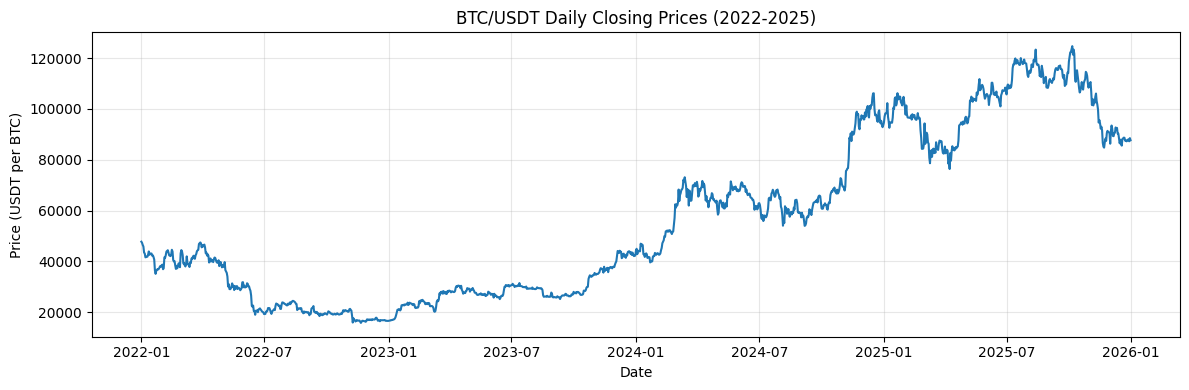

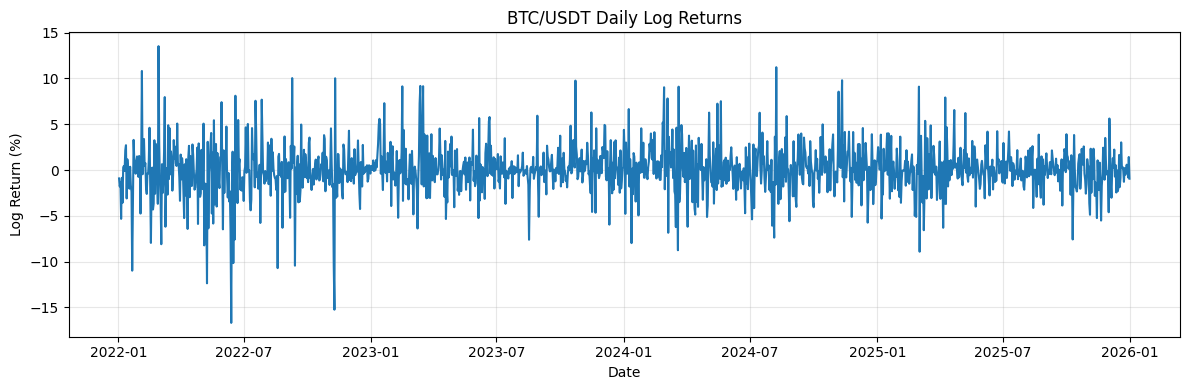

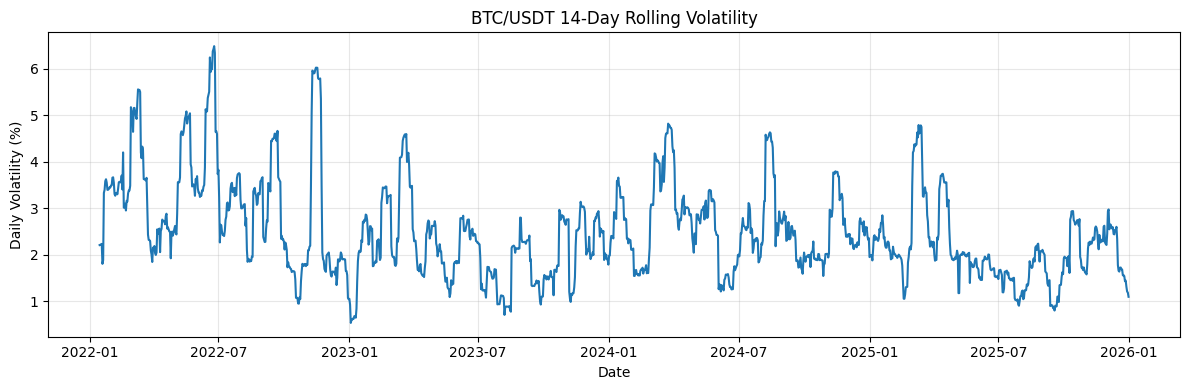

In [18]:

# Step 6: Historical data visualisation

import matplotlib.pyplot as plt

# Graph 1: Bitcoin closing prices
plt.figure(figsize=(12, 4))
plt.plot(price_df["date"], price_df["close"])
plt.title("BTC/USDT Daily Closing Prices (2022-2025)")
plt.xlabel("Date")
plt.ylabel("Price (USDT per BTC)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Daily log returns
plt.figure(figsize=(12, 4))
plt.plot(
    price_df["date"],
    price_df["log_return"] * 100
)
plt.title("BTC/USDT Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Log Return (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 3: Rolling volatility
plt.figure(figsize=(12, 4))
plt.plot(
    price_df["date"],
    price_df["rolling_vol_14d"] * 100
)
plt.title("BTC/USDT 14-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Daily Volatility (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.5 Calibration and Evaluation Dataset Split

The historical BTC/USDT dataset is divided chronologically into two periods:

- Calibration: 1 January 2022 to 31 December 2024.
- Evaluation: 1 January 2025 to 31 December 2025.

The calibration dataset is used to estimate the parameters of the GBM and Markov regime-switching models.

The evaluation dataset is reserved for assessing model performance on later observations.

This chronological split helps prevent future-information leakage. The evaluation data will not be used to estimate the model parameters or select the volatility-regime threshold.

In [19]:

# Step 7: Chronological dataset split

cutoff = pd.Timestamp("2025-01-01", tz="UTC")

calibration_df = price_df[
    price_df["date"] < cutoff
].copy()

evaluation_df = price_df[
    price_df["date"] >= cutoff
].copy()

# Verify the expected sizes
assert len(calibration_df) == 1096, \
    "Unexpected calibration period length"

assert len(evaluation_df) == 365, \
    "Unexpected evaluation period length"

# Estimate preliminary baseline parameters
cal_returns = calibration_df["log_return"].dropna()

mu_cal = cal_returns.mean()
sigma_cal = cal_returns.std(ddof=1)

assert np.isfinite(mu_cal)
assert np.isfinite(sigma_cal) and sigma_cal > 0

print("Calibration observations:", len(calibration_df))
print("Evaluation observations:", len(evaluation_df))

print(f"Mean daily log return: {mu_cal:.6f}")
print(f"Daily log-return volatility: {sigma_cal:.6f}")
print(f"Daily volatility (%): {sigma_cal * 100:.3f}%")

print("PASS: Chronological data split completed")


Calibration observations: 1096
Evaluation observations: 365
Mean daily log return: 0.000615
Daily log-return volatility: 0.028460
Daily volatility (%): 2.846%
PASS: Chronological data split completed


## 4. Verification

**Foundational checks below verify only the foundational computations.** They must not be presented as verification of the final Bitcoin simulation. Future independent checks will include:

1. GBM Monte Carlo loss probability versus its analytic lognormal formula.
2. A limiting case: identical return distributions in both regimes should match the single-distribution benchmark within Monte Carlo error.
3. Row-sum and range checks for the real transition matrix.
4. Error-scaling study: estimate how Monte Carlo error decreases as simulation count grows, with a log–log plot.
5. A browser-versus-notebook reference test with a stated tolerance.

In [20]:
# Verification of the *foundational* calculations (fictional data only).
np.testing.assert_allclose(np.exp(toy_log), 1.0 + toy_simple, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(toy_log.sum(), np.log(toy_prices[-1] / toy_prices[0]), rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(toy_transition_matrix.sum(axis=1), np.ones(2), atol=1e-12)
assert np.all((toy_transition_matrix >= 0) & (toy_transition_matrix <= 1))

print("PASS: log returns and simple returns are mathematically consistent")
print("PASS: log returns add across the complete price interval")
print("PASS: illustrative Markov transition probabilities are valid")
print("NOTE: full GBM and regime-simulation verification has not yet been performed")

PASS: log returns and simple returns are mathematically consistent
PASS: log returns add across the complete price interval
PASS: illustrative Markov transition probabilities are valid
NOTE: full GBM and regime-simulation verification has not yet been performed


## 5. Experiments and results

**No empirical experiment results have been generated yet.** The experiment table below is a *plan*, not evidence.

| Experiment | Comparison / change | Main output |
|---|---|---|
| Primary model comparison | GBM vs two-state Markov model on identical calibration data | 30-day loss probabilities, 95% VaR, 95% ES |
| Threshold sensitivity | 10%, 20%, 35% losses | Estimated event probabilities and confidence intervals |
| Horizon sensitivity | Example: 7, 30, 90 days | How risk changes with horizon |
| Regime sensitivity | Transition persistence and volatility assumptions | Effect on model-estimated downside risk |
| Convergence | Increasing path counts and independent seeds | Error versus $N^{-1/2}$ behavior |
| Held-out evaluation | 2025 observations, without fitting on 2025 data | Limited, transparent out-of-sample risk assessment |

**Planned minimum numerical settings:** 10,000 paths per principal scenario, recorded seed(s), multiple replications as feasible. Monte Carlo uncertainty is not the same as uncertainty about model assumptions. A single 2025 evaluation year may contain few independent extreme-loss events.

## 6. Discussion and limitations

The eventual conclusion must be based on verified experiments. We must not assume beforehand that regime switching performs better merely because volatility changes over time.

**Current limitations (Day 2):** Historical BTC/USDT data has been collected and analysed, but the full GBM and Markov regime-switching simulations have not yet been implemented. No final model-comparison results or downside-risk estimates are available.

**Expected final limitations:** Simplified two-state dynamics, normal conditional returns despite potential heavy tails, sensitivity to regime definitions, crypto market structural changes, USDT-denominated price data, and sparse independent extreme-loss observations in the held-out period.

**Web demo reference result:** To be populated from a verified notebook calculation after both models are implemented. Do **not** invent a reference number or tolerance.

**Next development step:** Implement and independently verify the constant-volatility GBM baseline using parameters estimated from the 2022–2024 calibration period. Preserve the 2025 evaluation observations for out-of-sample assessment.


## 7. References

These are **starting sources**. Read and verify the publication details and dataset terms before citing them in a completed research report.

1. Binance, "Binance Public Data," GitHub repository. [Online]. Available: https://github.com/binance/binance-public-data (historical BTC/USDT data source).
2. F. Black and M. Scholes, "The pricing of options and corporate liabilities," *Journal of Political Economy*, vol. 81, no. 3, pp. 637–654, 1973, doi: [10.1086/260062](https://doi.org/10.1086/260062) (background on lognormal asset-price modelling).
3. A. M. Law, *Simulation Modeling and Analysis*, 5th ed., McGraw-Hill, 2015 (simulation design and verification background).

Additional peer-reviewed studies on Bitcoin volatility and regime-switching models will be reviewed for the full literature discussion.